# Concrete Compressive Strength Prediction

**Problem Statement**: Predict concrete compressive strength from mixture composition and curing age.

**Objective:** To develop a machine learning regression model that predicts the compressive strength of concrete based on its mixture composition and curing age, enabling accurate strength estimation and better concrete mix design.

**Dataset Audit:** https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength
* Number of instances 	1030
* Number of Attributes	9
* Attribute breakdown	8 quantitative input variables, and 1 quantitative output variable
* Missing Attribute Values	None

| Variable Name                 | Role    | Type       | Description                                               | Units | Missing Values |
| ----------------------------- | ------- | ---------- | --------------------------------------------------------- | ----- | -------------- |
| Cement                        | Feature | Continuous | Amount of cement used in the concrete mixture             | kg/m³ | No             |
| Blast Furnace Slag            | Feature | Integer    | Amount of blast furnace slag used as a cement replacement | kg/m³ | No             |
| Fly Ash                       | Feature | Continuous | Amount of fly ash used as a cement replacement            | kg/m³ | No             |
| Water                         | Feature | Continuous | Amount of water used in the concrete mixture              | kg/m³ | No             |
| Superplasticizer              | Feature | Continuous | Amount of superplasticizer added to improve workability   | kg/m³ | No             |
| Coarse Aggregate              | Feature | Continuous | Amount of coarse aggregate used in the concrete mixture   | kg/m³ | No             |
| Fine Aggregate                | Feature | Continuous | Amount of fine aggregate used in the concrete mixture     | kg/m³ | No             |
| Age                           | Feature | Integer    | Curing age of concrete before strength testing            | day   | No             |
| Concrete compressive strength | Target  | Continuous | Compressive strength of concrete measured after curing    | MPa   | No             |

**Project flow:** Load and validate the data → explore distributions and correlations → separate features and target → compare five regressors with repeated cross-validation → interpret Random Forest feature importance → tune Random Forest → evaluate on the held-out test set → estimate ingredient costs → screen strength-versus-cost candidates → summarize results and limitations.


**Research Questions**
1. How accurately can concrete compressive strength be predicted from mixture composition and curing age?
2. Which regression algorithm provides the strongest generalization performance?
3. Which input variables are most associated with predicted strength?
4. What trade-offs appear between estimated material cost and predicted strength?

**Assumptions**
- The dataset measurements are valid and representative of the mixtures being modeled.
- The target is the measured compressive strength in MPa.
- Predictions are intended for exploratory analysis and are not a substitute for laboratory testing or engineering approval.

**Intended Users**
Students and practitioners exploring data-driven concrete strength estimation and model comparison.


## 1. Problem Definition
### 1.1. Project Setup and Imports

In [1]:
# Import the libraries used throughout the project: data handling, visualization, regression models, validation, metrics, and hyperparameter search.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedKFold, cross_validate
from scipy.stats import randint

## Performing EDA to find distributions, missingness, outliers, class balance, correlations and visualizations.

## 2. Dataset Audit
### 2.1. Load the Dataset

In [2]:
# Load the concrete compressive-strength dataset from the Excel file.
df = pd.read_excel('Concrete_Data.xls')

### 2.2. Preview the Dataset

In [3]:
# Preview a few rows to verify that the dataset loaded and the columns look as expected.
df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


### 2.3. Missing-Value Audit

In [4]:
# Check each column for missing values before modeling.
df.isnull().sum()

Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64

### 2.4. Duplicate-Row Audit

In [5]:
# Identify exact duplicate rows. These are inspected rather than automatically deleted.
duplicates = df[df.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicates))
display(duplicates.sort_values(list(df.columns)))

Rows involved in duplicates: 36


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713


### 2.5. Repeated Mixture Audit

In [6]:
# Group rows with identical ingredient quantities to check whether repeated mixtures have different measured strengths.
features = df.columns[:-1]
target = df.columns[-1]

duplicate_groups = (
    df.groupby(list(features))[target]
      .agg(["size", "nunique", "mean", "std"])
)

duplicate_groups = duplicate_groups[
    duplicate_groups["size"] > 1
]

display(duplicate_groups)

size  \
Cement (component 1)(kg in a m^3 mixture) Blast Furnace Slag (component 2)(kg in a m^3 mi... Fly Ash (component 3)(kg in a m^3 mixture) Water  (component 4)(kg in a m^3 mixture) Superplasticizer (component 5)(kg in a m^3 mixt... Coarse Aggregate  (component 6)(kg in a m^3 mix... Fine Aggregate (component 7)(kg in a m^3 mixture) Age (day)         
252.0                                     0.0                                                0.0                                        185.0                                     0.00                                               1111.0                                             784.0                                             28            2   
359.0                                     19.0                                               141.0                                      154.0                                     10.91                                              942.0                                              801.0                                             3             2   
                                                                                                                                                                                                                                                                                                                                          7             2   
                                                                                                                                                                                                                                                                                                                                          28            2   
                                                                                                                                                                                                                                                                                                                                          56            2   
362.6                                     189.0                                              0.0                                        164.9                                     11.60                                              944.7                                              755.8                                             3             4   
                                                                                                                                                                                                                                                                                                                                          7             4   
                                                                                                                                                                                                                                                                                                                                          28            4   
                                                                                                                                                                                                                                                                                                                                          56            4   
                                                                                                                                                                                                                                                                                                                                          91            4   
425.0                                     106.3                                              0.0                                        153.5            

### 2.6. Data Types and Dataset Structure

In [7]:
# Inspect column names, data types, and non-null counts.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)        1030 

### 2.7. Descriptive Statistics

In [8]:
# Review descriptive statistics (count, mean, spread, quartiles, and ranges) for the dataset.
df.describe(include='all')

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


## 3. Exploratory Data Analysis (EDA)
### 3.1. Skewness Analysis

In [9]:
# Calculate skewness for numeric columns to identify asymmetric feature distributions.
numerical_df = df.select_dtypes(include="number")
skew_values = numerical_df.skew().sort_values(ascending=False)

In [10]:
# Display skewness values; skewness alone does not automatically require a transformation.
skew_values

Age (day)                                                3.269177
Superplasticizer (component 5)(kg in a m^3 mixture)      0.908113
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0.800737
Fly Ash (component 3)(kg in a m^3 mixture)               0.537445
Cement (component 1)(kg in a m^3 mixture)                0.509517
Concrete compressive strength(MPa, megapascals)          0.416922
Water  (component 4)(kg in a m^3 mixture)                0.074324
Coarse Aggregate  (component 6)(kg in a m^3 mixture)    -0.040206
Fine Aggregate (component 7)(kg in a m^3 mixture)       -0.252979
dtype: float64

### 3.2. Distribution Histograms

Plotting the skewness distribution

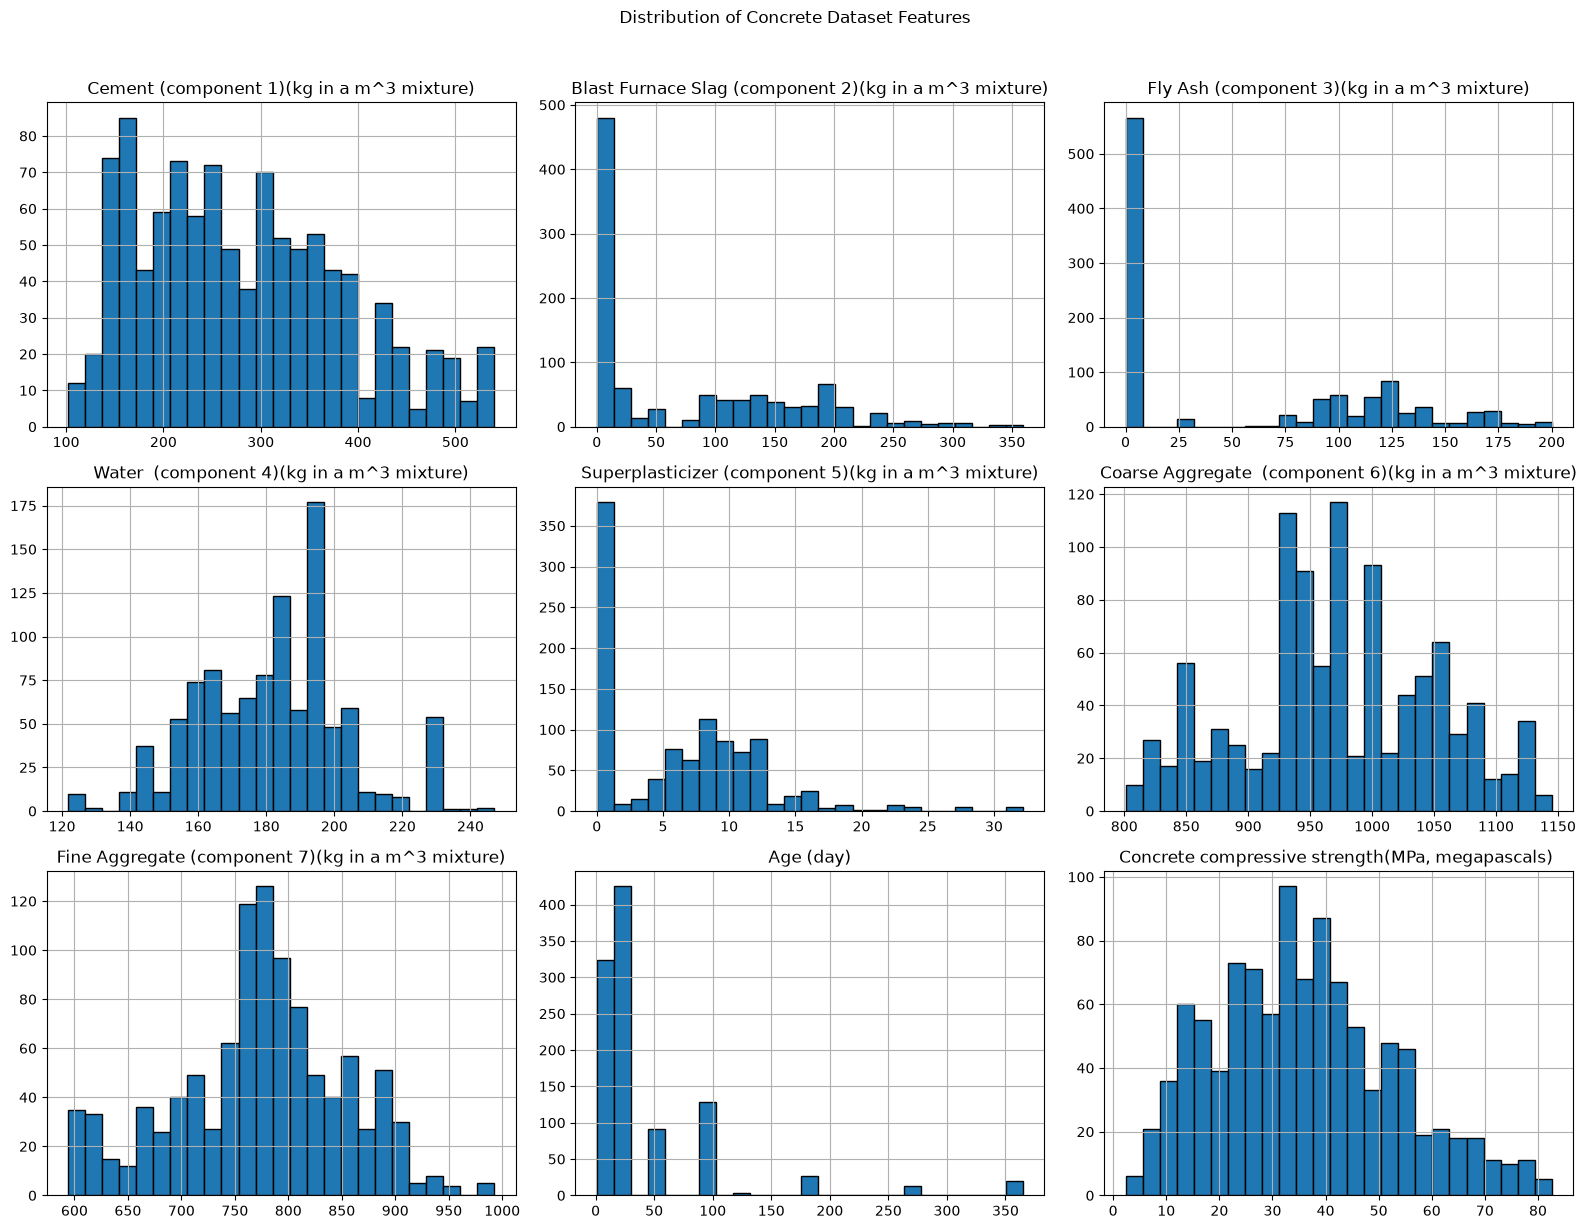

In [11]:
# Plot histograms for all numeric columns to inspect their distributions and ranges.
numerical_df.hist(figsize=(16,12), bins=25, edgecolor="black")
plt.suptitle("Distribution of Concrete Dataset Features", y=1.02)
plt.tight_layout()
plt.show()

### Outliers Boxplot


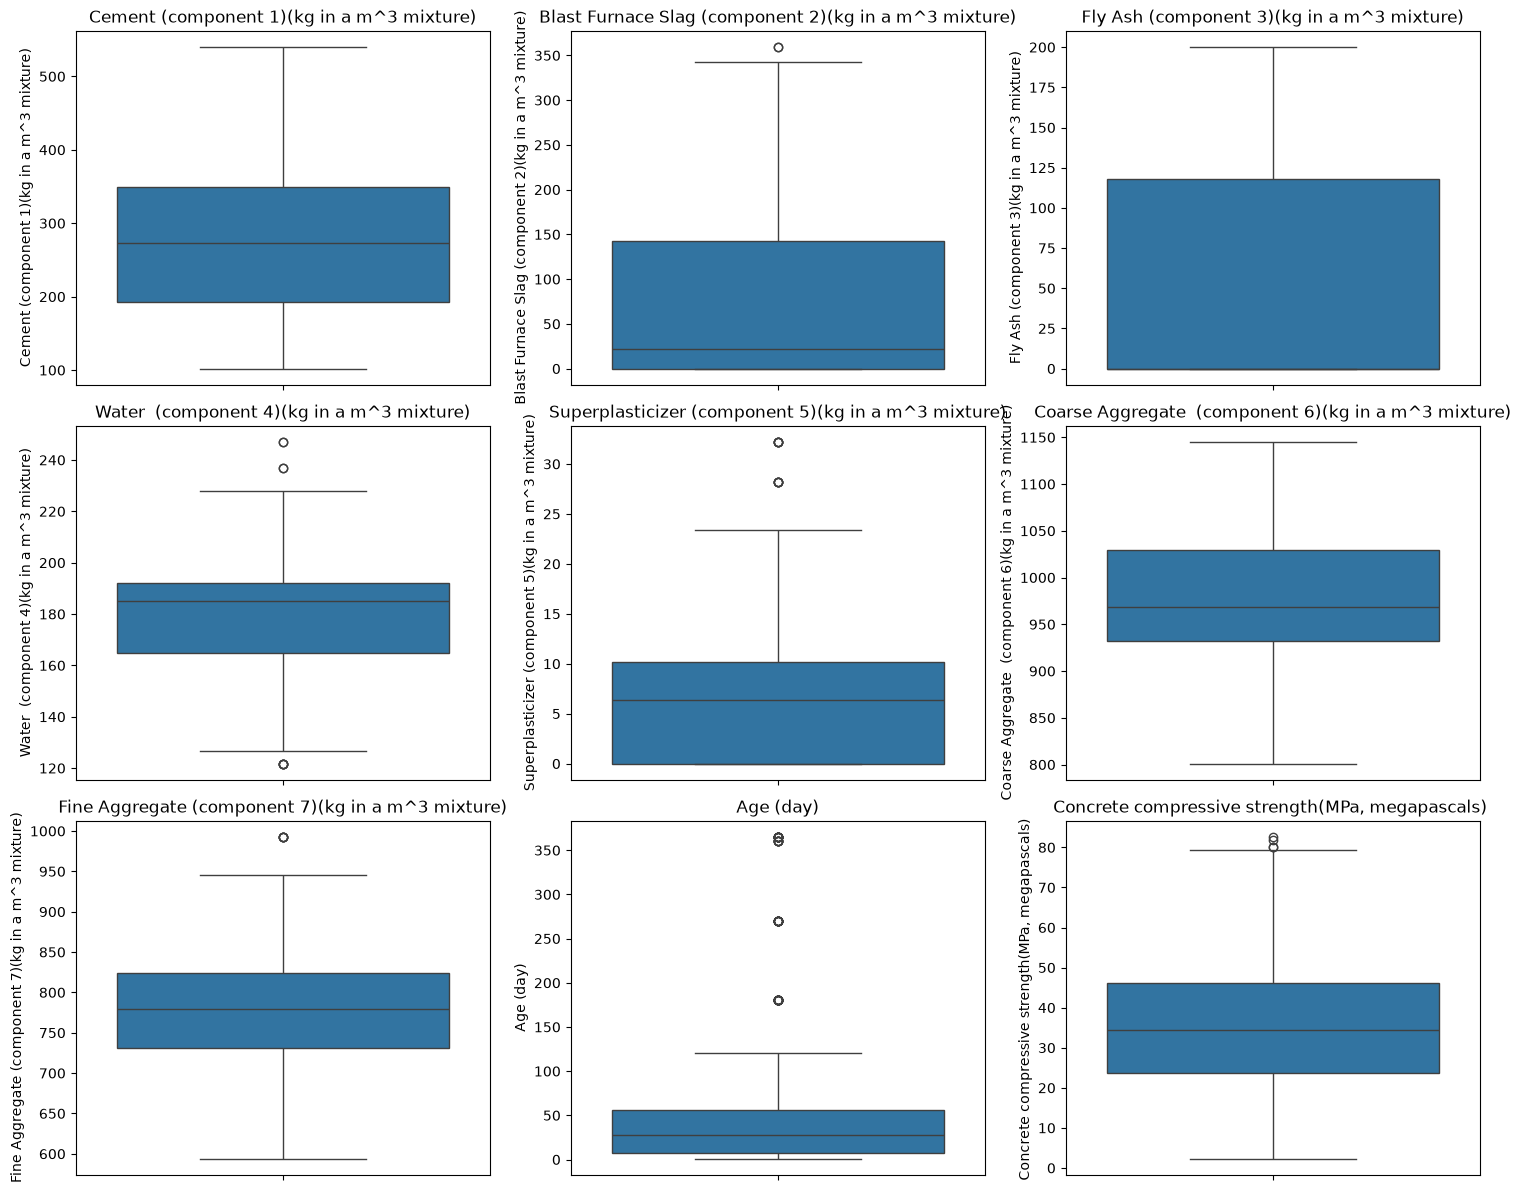

In [12]:
import math

columns = numerical_df.columns
n_cols = 3
n_rows = math.ceil(len(columns) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for ax, column in zip(axes, columns):
    sns.boxplot(y=numerical_df[column], ax=ax)
    ax.set_title(column)

# Hide any unused subplot axes
for ax in axes[len(columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### 3.3. Distributions of Selected Features

Visualizing the most skewed features

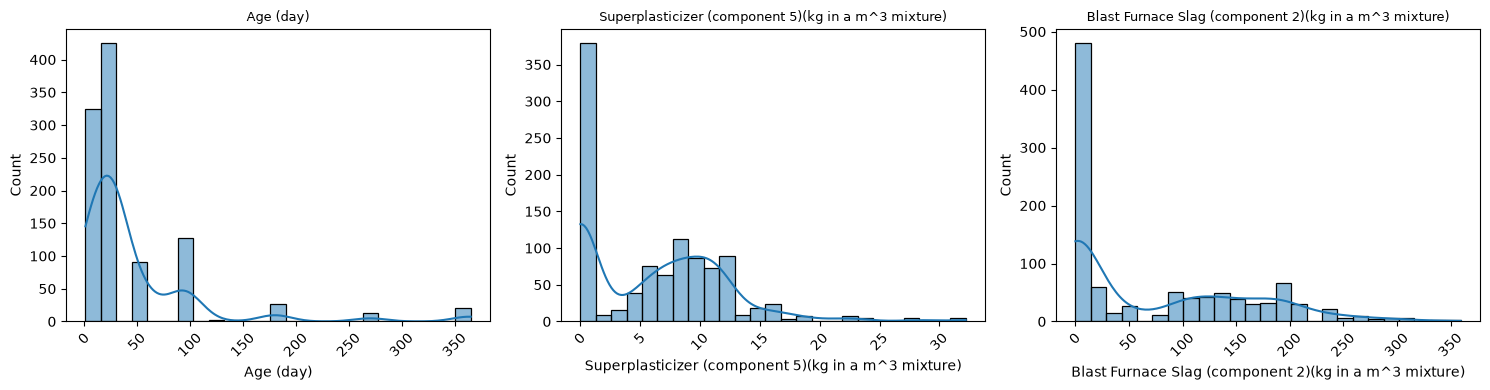

In [13]:
# Examine selected features with relatively strong skew using histograms and density curves.
features = [
    "Age (day)",
    "Superplasticizer (component 5)(kg in a m^3 mixture)",
    "Blast Furnace Slag (component 2)(kg in a m^3 mixture)"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, features):
    sns.histplot(df[col], bins=25, kde=True, ax=ax)
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

### 3.4. Correlation with the Target

Calculating correlation to the target feature

### 3.5. Identify the Target Variable

In [14]:
# Identify the target column (concrete compressive strength), which is the final dataset column.
target = df.columns[-1]

In [15]:
# Calculate Pearson correlations between each numeric feature and the target strength.
correlations = numerical_df.corr()[target]
correlations = correlations.drop(target).sort_values()
print(correlations)

Water  (component 4)(kg in a m^3 mixture)               -0.289613
Fine Aggregate (component 7)(kg in a m^3 mixture)       -0.167249
Coarse Aggregate  (component 6)(kg in a m^3 mixture)    -0.164928
Fly Ash (component 3)(kg in a m^3 mixture)              -0.105753
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0.134824
Age (day)                                                0.328877
Superplasticizer (component 5)(kg in a m^3 mixture)      0.366102
Cement (component 1)(kg in a m^3 mixture)                0.497833
Name: Concrete compressive strength(MPa, megapascals) , dtype: float64


### 3.6. Visualize Feature Correlations

Plotting the correlation with target feature

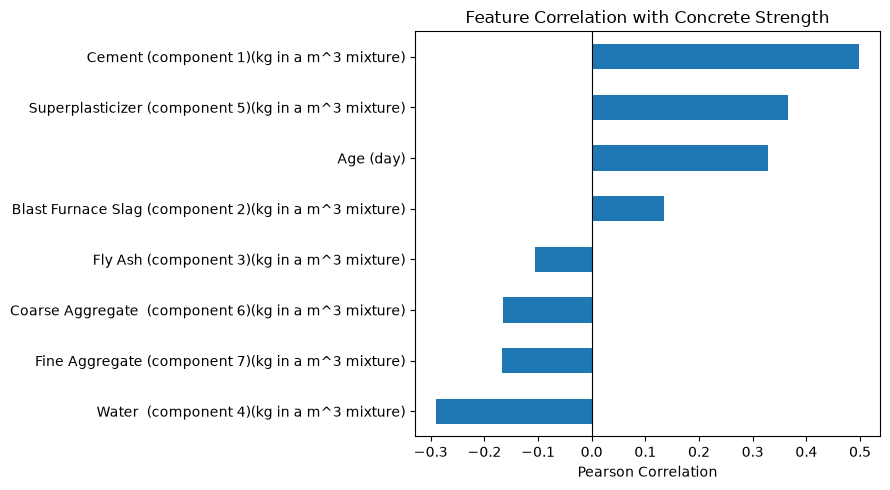

In [16]:
# Visualize the direction and magnitude of each feature's linear correlation with strength.
plt.figure(figsize=(9,5))
correlations.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Feature Correlation with Concrete Strength")
plt.xlabel("Pearson Correlation")
plt.tight_layout()
plt.show()

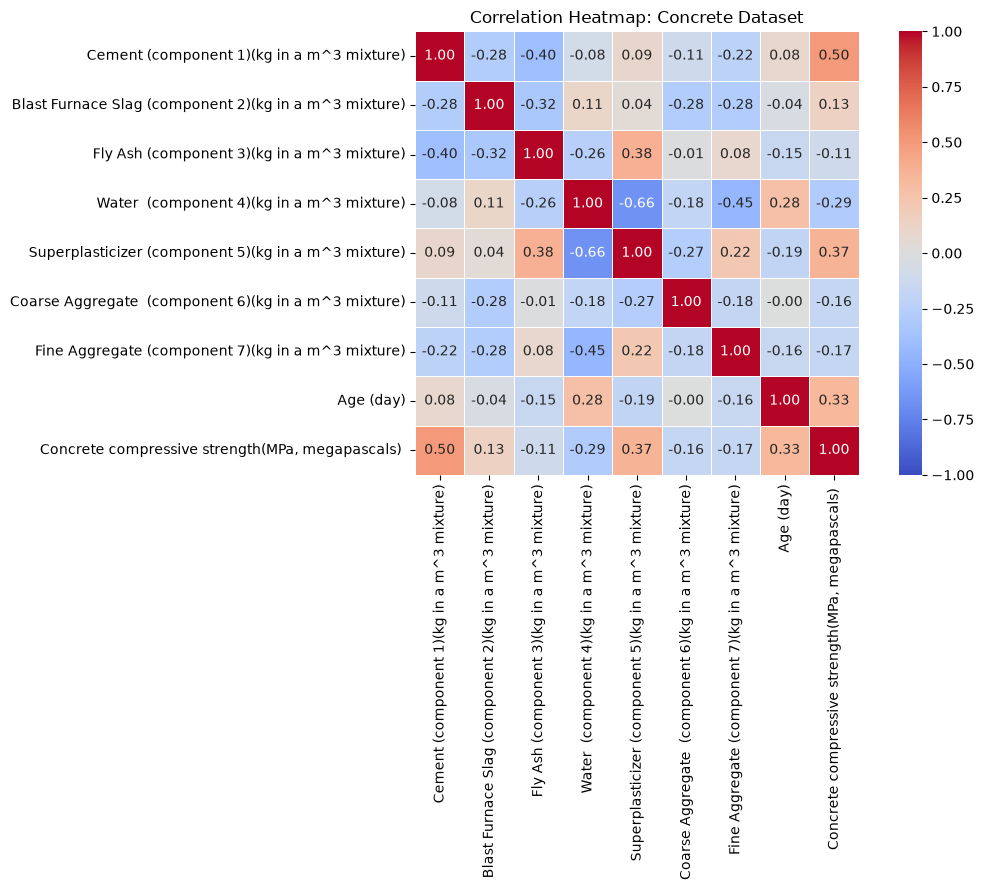

In [17]:
# Visualize the full correlation matrix for features and target.
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)
plt.title('Correlation Heatmap: Concrete Dataset')
plt.tight_layout()
plt.show()


## 4. Data Preprocessing
### 4.1. Separate Features and Target

Separating features and target

In [18]:
# Separate predictors (X: ingredient quantities and age) from the target (y: measured compressive strength).
X = df.iloc[:, : -1].copy()
y = df.iloc[:,-1].copy()

### 4.2. Verify Feature and Target Shapes

In [19]:
# Confirm the number of rows and columns in X and y.
print(X.shape, y.shape)

(1030, 8) (1030,)


### 4.3. Inspect Feature Names

In [20]:
# Inspect predictor names to verify that the expected input features are included.
X.columns.tolist()

['Cement (component 1)(kg in a m^3 mixture)',
 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
 'Fly Ash (component 3)(kg in a m^3 mixture)',
 'Water  (component 4)(kg in a m^3 mixture)',
 'Superplasticizer (component 5)(kg in a m^3 mixture)',
 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
 'Fine Aggregate (component 7)(kg in a m^3 mixture)',
 'Age (day)']

### 4.4. Train-Test Split

In [21]:
# Hold out 20% of the data for the final evaluation; the remaining 80% is used for cross-validation and model selection.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (824, 8)
Testing features: (206, 8)
Training target: (824,)
Testing target: (206,)


## 5. Baseline Model
### 5.1. Define the Validation Strategy

Applying repeated k-folds

In [22]:
# Set up repeated 5-fold cross-validation: 5 folds repeated 3 times gives 15 validation scores per model.
rkf = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)


print("Number of folds:", 5)
print("Number of repeats:", 3)
print("Total evaluations per model:", 5 * 3)

Number of folds: 5
Number of repeats: 3
Total evaluations per model: 15


## 5. Baseline Model
### 5.2. Establish a Dummy Regression Baseline
The baseline predicts a constant training-target value. It provides a minimum reference that learned models should outperform. The test set remains untouched until final evaluation.

In [23]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate

baseline = DummyRegressor(strategy="mean")
baseline_scores = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=rkf,
    scoring={
        "mae": "neg_mean_absolute_error",
        "mse": "neg_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=-1
)

baseline_mae = -baseline_scores["test_mae"].mean()
baseline_rmse = np.sqrt(-baseline_scores["test_mse"]).mean()
baseline_r2 = baseline_scores["test_r2"].mean()

print(f"Baseline CV MAE:  {baseline_mae:.3f} MPa")
print(f"Baseline CV RMSE: {baseline_rmse:.3f} MPa")
print(f"Baseline CV R²:   {baseline_r2:.3f}")


Baseline CV MAE:  13.580 MPa
Baseline CV RMSE: 16.870 MPa
Baseline CV R²:   -0.007


## 6. Model Comparison
### 6.1. Select Suitable Regression Algorithms

Defining the regression models

In [24]:
# Define five regression algorithms to compare using the same training data and validation strategy.
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Random Forest Regression": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    ),
    "SVR": SVR(kernel="rbf")
}

print("Models defined:", len(models))

for name in models:
    print(name)

Models defined: 5
Linear Regression
Ridge
Random Forest Regression
Gradient Boosting
SVR


### 6.2. Compare Models with Cross-Validation

Evaluating all the five models

In [25]:
# Compare all five models with repeated cross-validation on the training split.
# Scaling is kept inside a Pipeline for Linear Regression, Ridge, and SVR so each fold learns scaling from its training fold only.
# MAE and RMSE are reported in MPa (lower is better); R² is higher-is-better.
results = []

for name, model in models.items():

    if name in ["Linear Regression", "Ridge", "SVR"]:
        model_to_evaluate = Pipeline([
            ("scaler", StandardScaler()),
            ("model", model)
        ])
    else:
        model_to_evaluate = model

    scores = cross_validate(
        model_to_evaluate,
        X_train,
        y_train,
        cv=rkf,
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    mae = -scores["test_mae"]
    rmse = np.sqrt(-scores["test_mse"])
    r2 = scores["test_r2"]

    results.append({
        "Model": name,
        "MAE": mae.mean(),
        "RMSE": rmse.mean(),
        "R2": r2.mean(),
        "R2 Std": r2.std()
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("RMSE").reset_index(drop=True)

display(results_df.round(4))

,Model,MAE,RMSE,R2,R2 Std
0,Random Forest Regression,3.6902,5.2405,0.9021,0.0181
1,Gradient Boosting,3.9221,5.3817,0.8971,0.0138
2,SVR,8.0263,10.2704,0.6264,0.0231
3,Ridge,8.4427,10.6686,0.5955,0.0378
4,Linear Regression,8.4353,10.6690,0.5954,0.0382


### 6.3. Inspect Random Forest Feature Importance

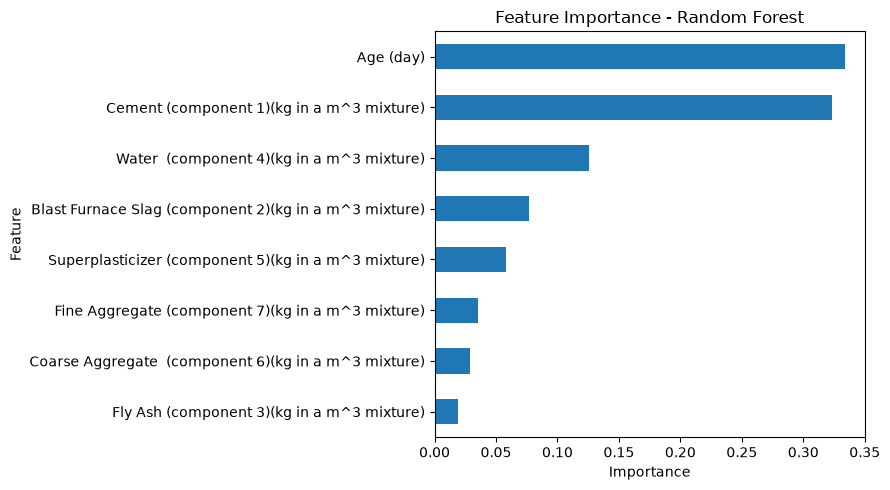

,Importance
Age (day),0.3336
Cement (component 1)(kg in a m^3 mixture),0.3231
Water (component 4)(kg in a m^3 mixture),0.1256
Blast Furnace Slag (component 2)(kg in a m^3 mixture),0.0770
Superplasticizer (component 5)(kg in a m^3 mixture),0.0579
Fine Aggregate (component 7)(kg in a m^3 mixture),0.0351
Coarse Aggregate (component 6)(kg in a m^3 mixture),0.0285
Fly Ash (component 3)(kg in a m^3 mixture),0.0191


In [26]:
# Fit the baseline Random Forest on the training split and inspect its impurity-based feature importances.
# These scores describe predictive usefulness, not causal effects.
# Train the baseline Random Forest on the training data
rf_model = models["Random Forest Regression"]
rf_model.fit(X_train, y_train)

# Calculate feature importance
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

# Plot feature importance
plt.figure(figsize=(9, 5))
importance.plot(kind="barh")

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Display numerical values
display(
    importance.sort_values(ascending=False)
    .to_frame("Importance")
    .round(4)
)

## 7. Validation and Hyperparameter Tuning
### 7.1. Tune Random Forest with Randomized Search

In [27]:
# Tune Random Forest hyperparameters using randomized search and the same repeated cross-validation splitter.
# The search selects the parameter combination with the lowest average validation RMSE; the test set is not used here.
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_distributions = {
    "n_estimators": randint(100, 501),
    "max_depth": [None, 10, 15, 20, 25, 30],
    "min_samples_split": randint(2, 11),
    "min_samples_leaf": randint(1, 5),
    "max_features": [1.0, "sqrt", 0.7]
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=rkf,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("Best CV RMSE:", round(-random_search.best_score_, 4))

Fitting 15 folds for each of 30 candidates, totalling 450 fits
Best parameters:
{'max_depth': 20, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 4, 'n_estimators': 463}
Best CV RMSE: 5.2326


## 8. Evaluation
### 8.1. Evaluate the Selected Model on the Held-Out Test Set

In [44]:
# Evaluate the best tuned Random Forest once on the held-out test set.
# These metrics estimate performance on unseen data and should be distinguished from baseline cross-validation scores.
best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = root_mean_squared_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)


print("Final Test Set Results")
print("----------------------")
print("MAE :", round(test_mae, 4))
print("RMSE:", round(test_rmse, 4))
print("R²  :", round(test_r2, 4))

Final Test Set Results
----------------------
MAE : 3.8753
RMSE: 5.5749
R²  : 0.8794


### 8.2. Actual vs. Predicted Plot

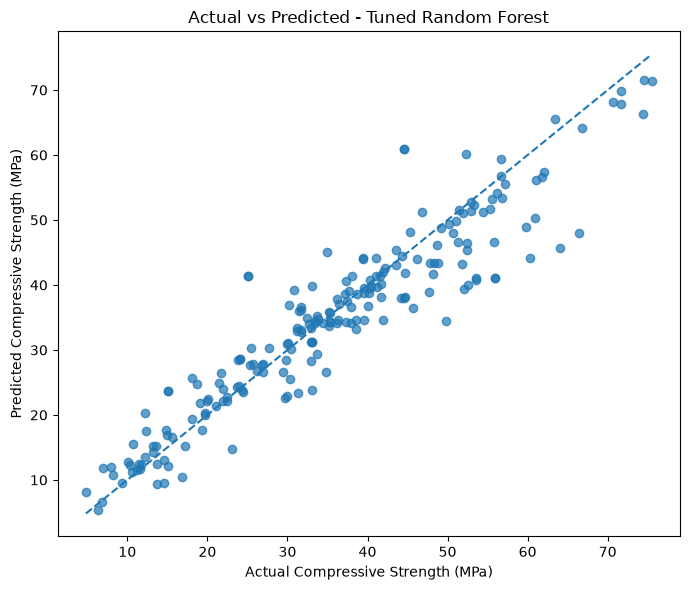

In [45]:
# Visualize test-set predictions against actual strengths. Points close to the diagonal represent more accurate predictions.
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Ideal predictions lie on this diagonal
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Compressive Strength (MPa)")
plt.ylabel("Predicted Compressive Strength (MPa)")
plt.title("Actual vs Predicted - Tuned Random Forest")
plt.tight_layout()
plt.show()

### 8.3. Residual Analysis and Error Distribution
Residuals are actual minus predicted strength. A random, roughly centered pattern is preferable; systematic structure can indicate model misspecification.

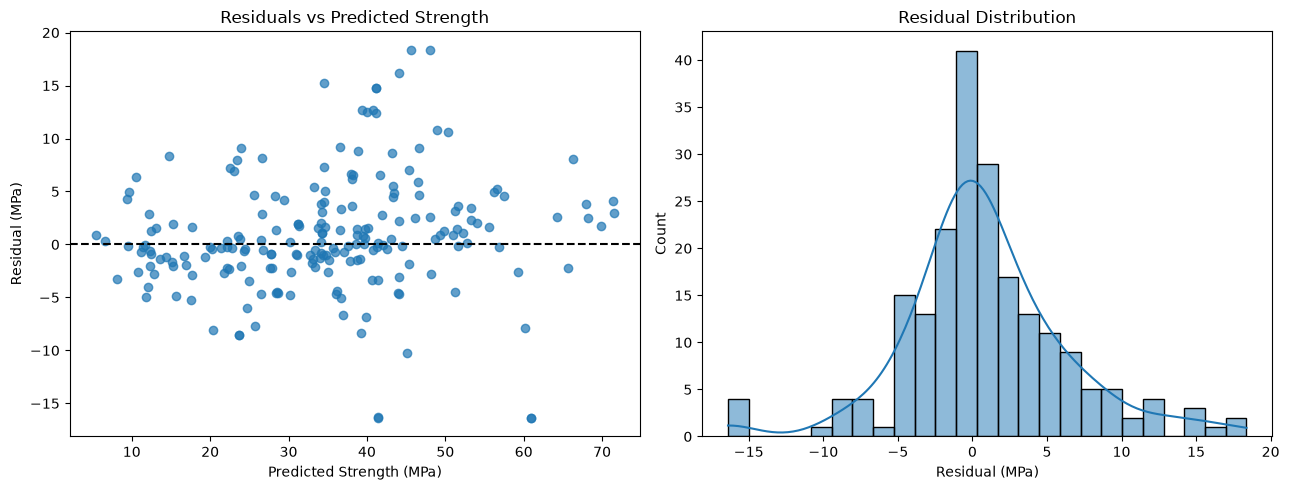

Mean residual: 0.8623 MPa
Median absolute error: 2.5546 MPa


In [46]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_pred, residuals, alpha=0.7)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_xlabel("Predicted Strength (MPa)")
axes[0].set_ylabel("Residual (MPa)")
axes[0].set_title("Residuals vs Predicted Strength")

sns.histplot(residuals, bins=25, kde=True, ax=axes[1])
axes[1].set_xlabel("Residual (MPa)")
axes[1].set_title("Residual Distribution")

plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 4), "MPa")
print("Median absolute error:", round(np.median(np.abs(residuals)), 4), "MPa")


## 9. Reproducibility
### 9.1. Random Seeds and Environment
This notebook uses fixed random seeds for splitting, cross-validation, and model search. Record the versions of the main libraries used to reproduce the analysis.

In [47]:
import sklearn
import scipy

print("Python environment should include:")
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)


Python environment should include:
pandas: 3.0.6
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2
scikit-learn: 1.9.1
SciPy: 1.18.1


### 9.2. Reproduction Instructions
1. Place `Concrete_Data.xls` in the notebook's working directory.
2. Install the required packages: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `scipy`, and `xlrd` (for reading `.xls`).
3. Run the notebook from top to bottom with the fixed random seeds shown in the code.
4. The reported test metrics are based on the held-out split created with `random_state=42`.

## 10. Model Artifact
### 10.1. Save the Selected Fitted Model
The fitted estimator is saved with joblib. Keep the package versions and feature order consistent when loading it.

In [48]:
import joblib

model_path = "concrete_strength_random_forest.joblib"
joblib.dump(best_model, model_path)
print(f"Saved model to: {model_path}")


Saved model to: concrete_strength_random_forest.joblib


### 10.2. Example Inference
Use one test observation as an example input. The example preserves the training feature names and order.

In [49]:
example_input = X_test.iloc[[0]].copy()
example_prediction = best_model.predict(example_input)[0]

print("Input mixture:")
display(example_input)
print(f"Predicted compressive strength: {example_prediction:.2f} MPa")


Input mixture:


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day)
31,266.0,114.0,0.0,228.0,0.0,932.0,670.0,365


Predicted compressive strength: 51.43 MPa


## 11. Research Contribution
### 11.1. Define Illustrative Material Prices

In [50]:
# Define illustrative ingredient prices (INR/kg) for the cost analysis. Replace these placeholders with verified local prices when available.
ingredient_prices = {
    "Cement": 7.0,
    "Blast Furnace Slag": 1.0,
    "Fly Ash": 0.8,
    "Water": 0.05,
    "Superplasticizer": 40.0,
    "Coarse Aggregate": 0.8,
    "Fine Aggregate": 0.7
}

print("Ingredient prices (INR/kg):")

for ingredient, price in ingredient_prices.items():
    print(f"{ingredient}: ₹{price}")

Ingredient prices (INR/kg):
Cement: ₹7.0
Blast Furnace Slag: ₹1.0
Fly Ash: ₹0.8
Water: ₹0.05
Superplasticizer: ₹40.0
Coarse Aggregate: ₹0.8
Fine Aggregate: ₹0.7


### 11.2. Estimate Material Cost

In [51]:
# Estimate material cost per cubic metre by multiplying each ingredient quantity (kg/m³) by its assumed price (INR/kg) and summing the costs. Labor, transport, equipment, and overheads are excluded.
df_cost = df.copy()

df_cost["Estimated Cost (INR/m³)"] = (
    df_cost["Cement (component 1)(kg in a m^3 mixture)"] * ingredient_prices["Cement"]
    + df_cost["Blast Furnace Slag (component 2)(kg in a m^3 mixture)"] * ingredient_prices["Blast Furnace Slag"]
    + df_cost["Fly Ash (component 3)(kg in a m^3 mixture)"] * ingredient_prices["Fly Ash"]
    + df_cost["Water  (component 4)(kg in a m^3 mixture)"] * ingredient_prices["Water"]
    + df_cost["Superplasticizer (component 5)(kg in a m^3 mixture)"] * ingredient_prices["Superplasticizer"]
    + df_cost["Coarse Aggregate  (component 6)(kg in a m^3 mixture)"] * ingredient_prices["Coarse Aggregate"]
    + df_cost["Fine Aggregate (component 7)(kg in a m^3 mixture)"] * ingredient_prices["Fine Aggregate"]
)

display(
    df_cost[[
        "Age (day)",
        "Concrete compressive strength(MPa, megapascals) ",
        "Estimated Cost (INR/m³)"
    ]].head(10).round(2)
)

,Age (day),"Concrete compressive strength(MPa, megapascals)",Estimated Cost (INR/m³)
0,28,79.99,5193.30
1,28,61.89,5205.30
2,270,40.27,3642.80
3,365,41.05,3642.80
4,360,44.30,2892.77
5,90,47.03,3202.00
6,365,43.70,3927.80
7,28,36.45,3927.80
8,28,45.85,3202.00
9,28,39.29,4497.80


### 11.3. Explore Cost-Strength Relationship

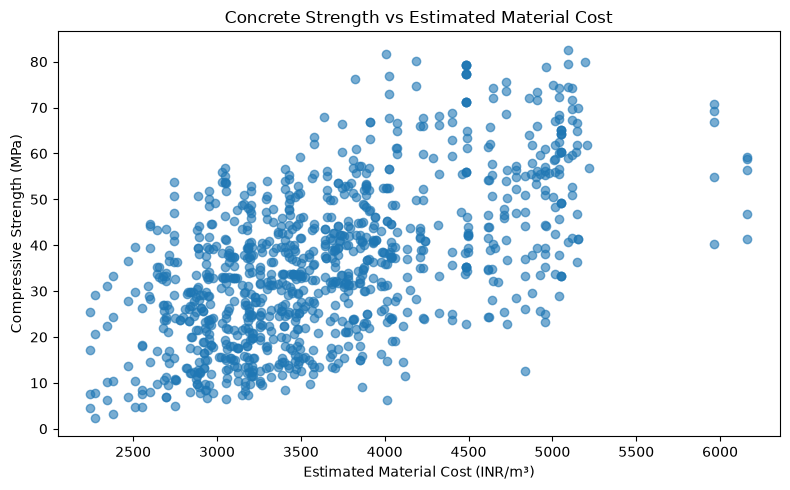

In [52]:
# Explore the relationship between estimated material cost and observed compressive strength across the dataset.
plt.figure(figsize=(8, 5))

plt.scatter(
    df_cost["Estimated Cost (INR/m³)"],
    df_cost["Concrete compressive strength(MPa, megapascals) "],
    alpha=0.6
)

plt.xlabel("Estimated Material Cost (INR/m³)")
plt.ylabel("Compressive Strength (MPa)")
plt.title("Concrete Strength vs Estimated Material Cost")
plt.tight_layout()
plt.show()

### 11.4. Identify Observed Mixtures Meeting the Strength Target

In [53]:
# Find observed mixtures whose measured strength meets the illustrative 40 MPa target, then sort them by estimated material cost.
# This first filter does not control curing age.
target_strength = 40  # MPa

eligible_mixtures = df_cost[
    df_cost["Concrete compressive strength(MPa, megapascals) "] >= target_strength
].copy()

eligible_mixtures = eligible_mixtures.sort_values(
    "Estimated Cost (INR/m³)"
)

print("Target strength:", target_strength, "MPa")
print("Number of eligible mixtures:", len(eligible_mixtures))

display(
    eligible_mixtures[
        [
            "Cement (component 1)(kg in a m^3 mixture)",
            "Age (day)",
            "Concrete compressive strength(MPa, megapascals) ",
            "Estimated Cost (INR/m³)"
        ]
    ].head(10).round(2)
)

Target strength: 40 MPa
Number of eligible mixtures: 379


,Cement (component 1)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)",Estimated Cost (INR/m³)
66,139.6,360,44.70,2598.63
23,139.6,180,44.21,2598.63
647,157.0,90,43.38,2639.76
719,166.8,90,43.57,2693.28
68,190.0,28,40.86,2746.00
34,190.0,365,53.69,2746.00
63,190.0,270,50.66,2746.00
51,190.0,180,46.93,2746.00
13,190.0,90,42.33,2746.00
707,200.0,90,43.25,2879.26


### 11.5. Compare Mixtures at a Fixed Curing Age

In [54]:
# Make the comparison fairer by fixing curing age at 28 days and keeping only mixtures with observed strength >= 40 MPa.
target_strength = 40
target_age = 28

eligible_28day = df_cost[
    (df_cost["Age (day)"] == target_age) &
    (df_cost["Concrete compressive strength(MPa, megapascals) "] >= target_strength)
].copy()

eligible_28day = eligible_28day.sort_values(
    "Estimated Cost (INR/m³)"
)

print("Target strength:", target_strength, "MPa")
print("Target age:", target_age, "days")
print("Qualifying mixtures:", len(eligible_28day))

display(
    eligible_28day[
        [
            "Cement (component 1)(kg in a m^3 mixture)",
            "Water  (component 4)(kg in a m^3 mixture)",
            "Superplasticizer (component 5)(kg in a m^3 mixture)",
            "Concrete compressive strength(MPa, megapascals) ",
            "Estimated Cost (INR/m³)"
        ]
    ].head(10).round(2)
)

Target strength: 40 MPa
Target age: 28 days
Qualifying mixtures: 146


,Cement (component 1)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),"Concrete compressive strength(MPa, megapascals)",Estimated Cost (INR/m³)
68,190.00,228.00,0.00,40.86,2746.00
698,203.50,203.50,0.00,41.68,2951.70
1000,141.90,173.50,10.90,44.61,2964.12
843,142.00,174.00,11.00,44.61,2969.60
395,200.00,190.00,0.00,49.25,2987.50
438,167.00,164.03,7.91,41.41,3047.51
433,165.00,175.06,8.08,46.39,3048.39
435,167.35,175.46,7.79,41.20,3052.28
8,266.00,228.00,0.00,45.85,3202.00
236,213.76,181.74,6.65,40.23,3291.75


### 11.6. Generate Predicted Strengths for Candidate Mixtures

In [55]:
# Use the tuned Random Forest to predict strength for the qualifying 28-day mixtures, allowing observed and predicted strengths to be compared.
candidate_features = eligible_28day[X.columns]

eligible_28day["Predicted Strength (MPa)"] = (
    best_model.predict(candidate_features)
)

display(
    eligible_28day[
        [
            "Age (day)",
            "Concrete compressive strength(MPa, megapascals) ",
            "Predicted Strength (MPa)",
            "Estimated Cost (INR/m³)"
        ]
    ]
    .sort_values("Estimated Cost (INR/m³)")
    .head(10)
    .round(2)
)

,Age (day),"Concrete compressive strength(MPa, megapascals)",Predicted Strength (MPa),Estimated Cost (INR/m³)
68,28,40.86,38.39,2746.00
698,28,41.68,39.88,2951.70
1000,28,44.61,38.28,2964.12
843,28,44.61,37.98,2969.60
395,28,49.25,41.31,2987.50
438,28,41.41,40.95,3047.51
433,28,46.39,43.26,3048.39
435,28,41.20,41.32,3052.28
8,28,45.85,44.10,3202.00
236,28,40.23,36.04,3291.75


### 11.7. Filter Predicted Candidates by Strength

In [56]:
# Keep only 28-day candidates whose model-predicted strength meets the 40 MPa target, then rank them by estimated cost.
target_strength = 40

predicted_eligible = eligible_28day[
    eligible_28day["Predicted Strength (MPa)"] >= target_strength
].copy()

predicted_eligible = predicted_eligible.sort_values(
    "Estimated Cost (INR/m³)"
)

print("Required predicted strength:", target_strength, "MPa")
print("Qualifying candidates:", len(predicted_eligible))

display(
    predicted_eligible[
        [
            "Cement (component 1)(kg in a m^3 mixture)",
            "Age (day)",
            "Concrete compressive strength(MPa, megapascals) ",
            "Predicted Strength (MPa)",
            "Estimated Cost (INR/m³)"
        ]
    ].head(10).round(2)
)

Required predicted strength: 40 MPa
Qualifying candidates: 137


,Cement (component 1)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)",Predicted Strength (MPa),Estimated Cost (INR/m³)
395,200.00,28,49.25,41.31,2987.50
438,167.00,28,41.41,40.95,3047.51
433,165.00,28,46.39,43.26,3048.39
435,167.35,28,41.20,41.32,3052.28
8,266.00,28,45.85,44.10,3202.00
366,214.90,28,52.20,51.72,3405.64
14,304.00,28,47.81,43.88,3430.00
346,213.74,28,40.15,41.48,3436.36
442,213.50,28,44.64,41.89,3483.46
351,213.50,28,45.94,43.31,3492.70


### 11.8. Visualize Cost-Strength Trade-Off

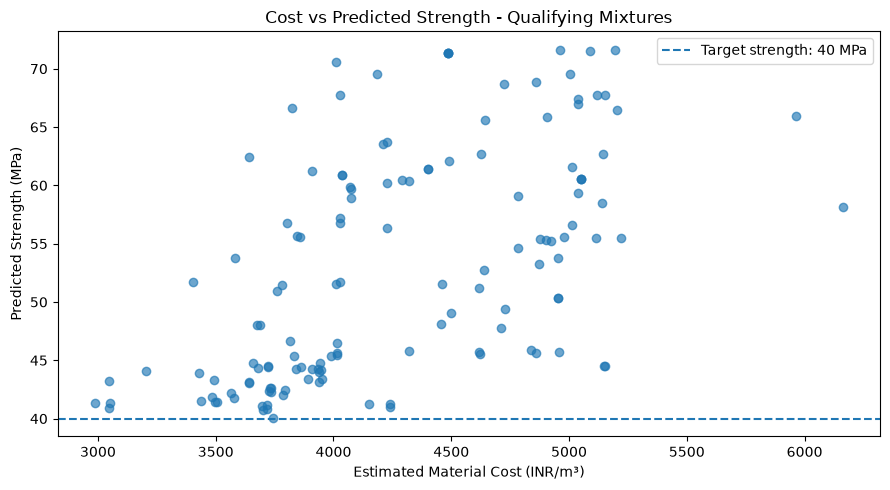

In [57]:
# Visualize the cost-versus-predicted-strength trade-off for the qualifying candidates; the dashed line marks the target strength.
plt.figure(figsize=(9, 5))

plt.scatter(
    predicted_eligible["Estimated Cost (INR/m³)"],
    predicted_eligible["Predicted Strength (MPa)"],
    alpha=0.65
)

plt.axhline(
    y=target_strength,
    linestyle="--",
    label="Target strength: 40 MPa"
)

plt.xlabel("Estimated Material Cost (INR/m³)")
plt.ylabel("Predicted Strength (MPa)")
plt.title("Cost vs Predicted Strength - Qualifying Mixtures")
plt.legend()
plt.tight_layout()
plt.show()

### 11.9. Pareto Trade-Off Analysis

In [58]:
# Identify Pareto candidates: after sorting by cost, retain mixtures whose predicted strength improves on all cheaper candidates.
# These are trade-off options, not validated engineering recommendations.
# Sort by cost, from lowest to highest
pareto_df = predicted_eligible.sort_values(
    "Estimated Cost (INR/m³)"
).copy()

# Keep candidates whose predicted strength exceeds
# the maximum strength among all cheaper candidates
pareto_df["Best Strength So Far"] = (
    pareto_df["Predicted Strength (MPa)"].cummax()
)

pareto_df = pareto_df[
    pareto_df["Predicted Strength (MPa)"]
    >= pareto_df["Best Strength So Far"]
].copy()

print("Pareto-optimal candidates:", len(pareto_df))

display(
    pareto_df[
        [
            "Age (day)",
            "Concrete compressive strength(MPa, megapascals) ",
            "Predicted Strength (MPa)",
            "Estimated Cost (INR/m³)"
        ]
    ].round(2)
)

Pareto-optimal candidates: 14


,Age (day),"Concrete compressive strength(MPa, megapascals)",Predicted Strength (MPa),Estimated Cost (INR/m³)
395,28,49.25,41.31,2987.50
433,28,46.39,43.26,3048.39
8,28,45.85,44.10,3202.00
366,28,52.20,51.72,3405.64
361,28,55.51,53.75,3580.14
400,28,67.87,62.42,3639.95
404,28,76.24,66.62,3822.60
381,28,81.75,70.58,4010.75
134,28,71.30,71.37,4484.27
129,28,71.30,71.37,4484.27


### 11.10. Summarize Model Comparison and Test Evaluation

In [59]:
# Present the baseline cross-validation comparison and the tuned Random Forest's separate held-out test metrics in one final summary.
# Note that these are different evaluation stages and should not be compared as if they were identical.
final_comparison = results_df.copy()

final_comparison = final_comparison.rename(columns={
    "MAE": "CV MAE (MPa)",
    "RMSE": "CV RMSE (MPa)",
    "R2": "CV R²",
    "R2 Std": "CV R² Std"
})

display(final_comparison.round(4))

print("\nTuned Random Forest - Final Test Results")
print("----------------------------------------")
print(f"Test MAE : {test_mae:.4f} MPa")
print(f"Test RMSE: {test_rmse:.4f} MPa")
print(f"Test R²  : {test_r2:.4f}")

,Model,CV MAE (MPa),CV RMSE (MPa),CV R²,CV R² Std
0,Random Forest Regression,3.6902,5.2405,0.9021,0.0181
1,Gradient Boosting,3.9221,5.3817,0.8971,0.0138
2,SVR,8.0263,10.2704,0.6264,0.0231
3,Ridge,8.4427,10.6686,0.5955,0.0378
4,Linear Regression,8.4353,10.6690,0.5954,0.0382



Tuned Random Forest - Final Test Results
----------------------------------------
Test MAE : 3.8753 MPa
Test RMSE: 5.5749 MPa
Test R²  : 0.8794


## 12. Final Presentation
### 12.1. Conclusion, Limitations, and Future Work
## Conclusion

Five regression algorithms were evaluated for predicting concrete compressive strength: Linear Regression, Ridge Regression, Support Vector Regression (SVR), Random Forest Regression, and Gradient Boosting Regression.

Random Forest achieved the best baseline cross-validation performance, with an MAE of 3.6902 MPa, RMSE of 5.2405 MPa, and R² of 0.9021. Gradient Boosting performed similarly, while SVR, Ridge, and Linear Regression had higher prediction errors.

After hyperparameter tuning, the Random Forest achieved a test MAE of 3.8753 MPa, RMSE of 5.5749 MPa, and R² of 0.8794. These results indicate that the model captures much of the variation in concrete compressive strength on unseen test data.

Feature-importance analysis identified concrete age and cement content as the two most influential features in the baseline Random Forest model.

A strength-versus-cost analysis was also conducted using assumed ingredient prices. Among the observed 28-day mixtures, 137 candidates had predicted compressive strength of at least 40 MPa. Pareto analysis identified 14 candidates representing different trade-offs between estimated material cost and predicted strength.

## Limitations

- Ingredient prices were illustrative assumptions rather than verified supplier quotations.
- The cost analysis covers material costs only and excludes labor, transportation, equipment, and overheads.
- The optimization considered observed dataset mixtures rather than searching all possible ingredient combinations.
- Feature importance indicates predictive usefulness, not causal influence.
- Model predictions are estimates and do not replace laboratory testing or engineering validation.
- Repeated or identical ingredient combinations may influence cross-validation performance; grouped validation could be investigated in future work.

## Future Scope

Future work could incorporate current local supplier prices, explore a wider range of candidate mixtures within experimentally supported limits, use grouped validation to assess generalization more rigorously, and validate promising formulations through laboratory testing.

### 12.2. Limitations and Responsible Use
- Material prices are illustrative assumptions and must be replaced with verified local prices before any cost claim is used.
- The dataset represents a finite set of laboratory mixtures; performance may change for mixtures, materials, or curing conditions outside its range.
- Feature importance describes model association, not causation.
- Predictions must not replace laboratory tests, applicable standards, or qualified engineering judgment.

### 12.3. Report, Slides, and Demonstration Checklist
- Summarize the dataset, preprocessing, model comparison, tuning, and held-out test results.
- Include key visualizations, limitations, ethical considerations, and future work.
- Demonstrate inference using a clearly specified mixture input.
